# Самостійна робота

**Тема:** Порівняння трьох класифікаторів на наборі Wine.

**Мета:** навчитися розділяти дані на навчальну та тестову вибірки, навчати класифікатори, порівнювати їх за macro-F1 і оцінювати найкращу модель.

У цьому варіанті використовуються базові моделі. Ноутбук запускається в Google Colab послідовно зверху вниз.

## 1. Імпорт бібліотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 42

## 2. Завантаження набору даних Wine

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="class")

print("Розмір набору даних:", X.shape)
print("Назви класів:", list(wine.target_names))
display(X.head())
print("\\nКількість об'єктів кожного класу:")
print(y.value_counts().sort_index())

Розмір набору даних: (178, 13)
Назви класів: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


\nКількість об'єктів кожного класу:
class
0    59
1    71
2    48
Name: count, dtype: int64


## 3. Поділ на навчальну та тестову вибірки

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)
print("\\nРозподіл класів у train:")
print(y_train.value_counts().sort_index())
print("\\nРозподіл класів у test:")
print(y_test.value_counts().sort_index())

Навчальна вибірка: (133, 13)
Тестова вибірка: (45, 13)
\nРозподіл класів у train:
class
0    44
1    53
2    36
Name: count, dtype: int64
\nРозподіл класів у test:
class
0    15
1    18
2    12
Name: count, dtype: int64


## 4. Створення класифікаторів

In [4]:
models = {
    "Логістична регресія": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "Дерево рішень": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)
}

## 5. Порівняння за macro-F1

Кросвалідація виконується лише на навчальній вибірці. Для всіх моделей використовуються однакові п'ять стратифікованих блоків.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    cv_results.append({
        "Модель": name,
        "Середній macro-F1": scores.mean(),
        "Стандартне відхилення": scores.std()
    })
    print(f"{name}:")
    print("Оцінки за блоками:", np.round(scores, 4))
    print(f"Середній macro-F1: {scores.mean():.4f}")
    print(f"Стандартне відхилення: {scores.std():.4f}\\n")

results_df = pd.DataFrame(cv_results).sort_values(
    by="Середній macro-F1", ascending=False
).reset_index(drop=True)
display(results_df)
best_name = results_df.loc[0, "Модель"]
print("Найкраща модель за CV:", best_name)

Логістична регресія:
Оцінки за блоками: [0.9619 0.9619 1.     0.9649 1.    ]
Середній macro-F1: 0.9777
Стандартне відхилення: 0.0182\n
Дерево рішень:
Оцінки за блоками: [0.8211 0.8926 0.9619 0.9649 0.8852]
Середній macro-F1: 0.9052
Стандартне відхилення: 0.0537\n
Random Forest:
Оцінки за блоками: [0.9269 1.     1.     1.     1.    ]
Середній macro-F1: 0.9854
Стандартне відхилення: 0.0292\n


,Модель,Середній macro-F1,Стандартне відхилення
0,Random Forest,0.985380,0.029240
1,Логістична регресія,0.977744,0.018205
2,Дерево рішень,0.905155,0.053687


Найкраща модель за CV: Random Forest


## 6. Навчання найкращої моделі та оцінювання на тесті

Тестова вибірка використовується лише для підсумкового оцінювання, а не для вибору моделі чи налаштувань.

In [6]:
best_model = models[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print("Обрана модель:", best_name)
print(f"Тестовий macro-F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

Обрана модель: Random Forest
Тестовий macro-F1: 1.0000


## 7. Матриця помилок

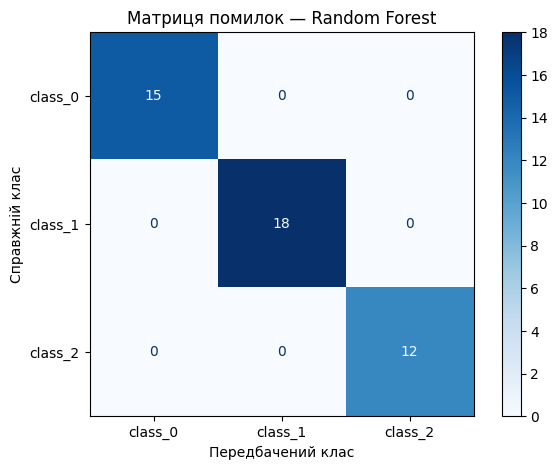

In [7]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Матриця помилок — {best_name}")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

## 8. Classification report

In [8]:
print(classification_report(
    y_test, y_pred, target_names=wine.target_names, digits=4
))

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        15
     class_1     1.0000    1.0000    1.0000        18
     class_2     1.0000    1.0000    1.0000        12

    accuracy                         1.0000        45
   macro avg     1.0000    1.0000    1.0000        45
weighted avg     1.0000    1.0000    1.0000        45



## 9. Висновок

Під час роботи було досліджено набір даних Wine, який містить характеристики вин трьох класів. Дані було стратифіковано поділено на навчальну та тестову вибірки у співвідношенні 75% до 25%. Було навчено три класифікатори: логістичну регресію, дерево рішень і Random Forest. Для порівняння моделей використано macro-F1 та п'ятиблокову стратифіковану кросвалідацію на навчальних даних. Найкращу модель обрано за середнім значенням macro-F1, після чого її перевірено на тестовій вибірці за допомогою матриці помилок і classification report. Логістична регресія потребує масштабування ознак, тому стандартизацію виконано всередині Pipeline. Однією з ознак можливого перенавчання є значно кращий результат на навчальних даних порівняно з результатами кросвалідації або тестування; надмірно складне дерево також може запам'ятовувати навчальні приклади.